<h1>Homework #1 - MongoDB</h1>

<p>L’esercizio richiede di caricare in MongoDB un dataset di film, applicare una validazione dei dati e rispondere a 5 domande analitiche. Il dataset è quello disponibile a questo <a href="https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows" target="_blank">link</a>.</p>

<p>Import delle librerie e delle classi necessarie allo svolgimento del compito</p>

In [1]:
import pandas as pd
from pymongo import MongoClient
import time
import matplotlib.pyplot as plt
import numpy as np

<p>Scaricare e salvare il database dentro un database MongoDB sotto forma di documenti JSON. Durante il salvataggio, organizzare in automatico i film in diverse collezioni a seconda del certificato acquisito da ciascun film (U=”Universal”, ovvero adatto a tutti; UA=”Parental Guidance”, ovvero da vedere con la presenza di una persona adulta; A=”Adult”). I film che non rientrano in nessuna delle categorie precedenti vanno salvati in una collezione a parte (“Trash”), così come tutti film usciti prima del 1980.</p>

In [2]:
# 1. Connessione a MongoDB (es. locale)
client = MongoClient("mongodb://localhost:27017/")

# 2. Scelgo il database
db = client["homework_2024"]
# Pulizia per esecuzioni ripetute
db.drop_collection("movies_U")
db.drop_collection("movies_UA")
db.drop_collection("movies_A")
db.drop_collection("trash")

# 3. Scelgo le collezioni per i diversi certificati
collezione_U = db["movies_U"]
collezione_UA = db["movies_UA"]
collezione_A = db["movies_A"]
collezione_other = db["trash"]

# 4. Leggo il CSV con pandas
df = pd.read_csv("imdb_top_1000.csv")
# normalizzo la colonna 'Genre' in modo che diventi una lista
def parse_genres(genre_str):
    if pd.isna(genre_str):
        return []  # nessun genere
    return [g.strip() for g in str(genre_str).split(",") if g.strip()]

df["Genre"] = df["Genre"].apply(parse_genres)

# 5. Converto le righe del DataFrame in dizionari
movies = df.to_dict(orient="records")

start_time = time.time()  # tempo iniziale
# 6. Validazione + inserimento
for movie in movies:
    cert = str(movie.get("Certificate", "")).strip()  # prendo il valore e tolgo spazi
    year = movie.get("Released_Year", None)

    # Controllo anno: se esiste e < 1980 va in trash
    if year is not None and str(year).isdigit() and int(year) < 1980:
        collezione_other.insert_one(movie)
    else:
        if cert == "U":
            collezione_U.insert_one(movie)
        elif cert == "UA":
            collezione_UA.insert_one(movie)
        elif cert == "A":
            collezione_A.insert_one(movie)
        else:
            # Tutto ciò che non è U, UA, A finisce comunque qui
            collezione_other.insert_one(movie)
            
end_time = time.time()  # tempo finale        

print("Caricamento completato!")

elapsed = end_time - start_time
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Caricamento completato!
Tempo di esecuzione: 0.4870 secondi


<h4>Versione alternativa del task precedente, implementato con l'uso del validatore</h4>

In [3]:
### VERSIONE ALTERNATIVA (CON VALIDATORI) ###
validator_year = {
    "$jsonSchema": {
        "bsonType": "object",
        "required":["Released_Year"],
        "properties":{
            "Released_Year":{
                "bsonType": "int",
                "minimum":1980
            }
        }
    }
}

# 2. Scelgo il database
db = client["homework_2024"]
# Pulizia per esecuzioni ripetute
db.drop_collection("movies_U")
db.drop_collection("movies_UA")
db.drop_collection("movies_A")
db.drop_collection("trash")

# 3. Creo le collezioni per i diversi certificati (con validator se necessario)
collezione_U = db.create_collection("movies_U", validator=validator_year)
collezione_UA = db.create_collection("movies_UA", validator=validator_year)
collezione_A = db.create_collection("movies_A", validator=validator_year)
collezione_other = db["trash"]

# 4. Leggo il CSV con pandas
df = pd.read_csv("imdb_top_1000.csv")
# converto la colonna in intero nullable
df["Released_Year"] = pd.to_numeric(df["Released_Year"], errors="coerce").astype("Int64")
# normalizzo la colonna 'Genre' in modo che diventi una lista
def parse_genres(genre_str):
    if pd.isna(genre_str):
        return []  # nessun genere
    return [g.strip() for g in str(genre_str).split(",") if g.strip()]

df["Genre"] = df["Genre"].apply(parse_genres)

# 5. Converto le righe del DataFrame in dizionari
movies = df.to_dict(orient="records")

start_time = time.time()  # tempo iniziale
# 6. Validazione + inserimento
for movie in movies:
    cert = str(movie.get("Certificate", "")).strip()  # prendo il valore e tolgo spazi

    if cert == "U":
        try:
            collezione_U.insert_one(movie)
        except:
            collezione_other.insert_one(movie)
    elif cert == "UA":
        try:
            collezione_UA.insert_one(movie)
        except:
            collezione_other.insert_one(movie)
    elif cert == "A":
        try:
            collezione_A.insert_one(movie)
        except:
            collezione_other.insert_one(movie)
    else:
        # Tutto ciò che non è U, UA, A finisce qui
        collezione_other.insert_one(movie)

end_time = time.time()  # tempo finale   

print("Caricamento completato!")
elapsed = end_time - start_time
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Caricamento completato!
Tempo di esecuzione: 0.6437 secondi


<h4>Caricamento in un'unica collezione</h4>
<p>Caricare i record come nei task precedenti, ma senza organizzare i film in diverse collezioni a seconda del certificato acquisito da ciascun film. Nello specifico, se il certificato del film appartiene ad una delle categorie U (”Universal”, ovvero adatto a tutti), UA (”Parental Guidance”, ovvero da vedere con la presenza di una persona adulta) oppure A (”Adult”), e il film è uscito dal 1980 in poi, il film essere salvato in un'unica collezione. I film che non rientrano in nessuna delle categorie precedenti, così come tutti film usciti prima del 1980, vanno salvati in una collezione a parte (“Trash”).</p>

In [4]:
# 2. Scelgo il database
db = client["homework_2024"]
# Pulizia per esecuzioni ripetute
db.drop_collection("trash")
db.drop_collection("all")

# 3. Scelgo una collezione unica per i certificati "U", "UA", "A"
collezione_all = db["all"]
collezione_other = db["trash"]

# 4. Leggo il CSV con pandas
df = pd.read_csv("imdb_top_1000.csv")
# normalizzo la colonna 'Genre' in modo che diventi una lista
def parse_genres(genre_str):
    if pd.isna(genre_str):
        return []  # nessun genere
    return [g.strip() for g in str(genre_str).split(",") if g.strip()]
df["Genre"] = df["Genre"].apply(parse_genres)

# 5. Converto le righe del DataFrame in dizionari
movies = df.to_dict(orient="records")

start_time = time.time()  # tempo iniziale
# 6. Validazione + inserimento
for movie in movies:
    cert = str(movie.get("Certificate", "")).strip()  # prendo il valore e tolgo spazi
    year = movie.get("Released_Year", None)

    # Controllo anno: se esiste e < 1980 va in trash
    if year is not None and str(year).isdigit() and int(year) < 1980:
        collezione_other.insert_one(movie)
    else:
        if cert == "U":
            collezione_all.insert_one(movie)
        elif cert == "UA":
            collezione_all.insert_one(movie)
        elif cert == "A":
            collezione_all.insert_one(movie)
        else:
            # Tutto ciò che non è U, UA, A finisce comunque qui
            collezione_other.insert_one(movie)
        
end_time = time.time()  # tempo finale   

print("Caricamento completato!")
elapsed = end_time - start_time
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Caricamento completato!
Tempo di esecuzione: 0.5876 secondi


<h4>Versione alternativa del task precedente, implementato con l'uso del validatore</h4>

In [5]:
### VERSIONE ALTERNATIVA (CON VALIDATORI) ###
validator_full = {
    "$jsonSchema": {
        "bsonType": "object",
        "required":["Released_Year","Certificate"],
        "properties":{
            "Released_Year":{
                "bsonType": "int",
                "minimum":1980
            },
            "Certificate":{
                "bsonType": "string",
                "enum":["U","UA","A"]
            }
        }
    }
}
# 2. Scelgo il database
db = client["homework_2024"]
# Pulizia per esecuzioni ripetute
db.drop_collection("trash")
db.drop_collection("all")

# 3. Creo le collezioni per i diversi certificati (con validator se necessario)
collezione_all = db.create_collection("all", validator=validator_full)
collezione_other = db["trash"]

# 4. Leggo il CSV con pandas
df = pd.read_csv("imdb_top_1000.csv")
# converto la colonna in intero nullable
df["Released_Year"] = pd.to_numeric(df["Released_Year"], errors="coerce").astype("Int64")
# normalizzo la colonna 'Genre' in modo che diventi una lista
def parse_genres(genre_str):
    if pd.isna(genre_str):
        return []  # nessun genere
    return [g.strip() for g in str(genre_str).split(",") if g.strip()]
df["Genre"] = df["Genre"].apply(parse_genres)

# 5. Converto le righe del DataFrame in dizionari
movies = df.to_dict(orient="records")

start_time = time.time()  # tempo iniziale
# 6. Validazione + inserimento
for movie in movies:
    cert = str(movie.get("Certificate", "")).strip()  # prendo il valore e tolgo spazi
    try:
        collezione_all.insert_one(movie)
    except:
        collezione_other.insert_one(movie)

end_time = time.time()  # tempo finale   

print("Caricamento completato!")
elapsed = end_time - start_time
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Caricamento completato!
Tempo di esecuzione: 0.5754 secondi


<h4>Query - Trovare i primi 5 film per ogni genere, sulla base del voto!</h4>
<p>Ripetere la query sia distinguendo per certificato acquisito da ciascun film che senza considerare tale distinzione. Fare delle considerazioni in merito alle tempistiche richieste da MongoDB in un caso (ovvero senza distinguere per certificato) e nell’altro. Come si potrebbe trarre il massimo vantaggio, in termini di tempi di risposta, volendo mantenere tutti e due i casi?</p>

In [6]:
# Pipeline che pesca dalla collezione unica e ranking per genere
pipeline = [
    # Esplodo i generi
    {"$unwind": "$Genre"},

    # Ordino per genere e rating decrescente
    {"$sort": {"Genre": 1, "IMDB_Rating": -1}},

    # Raggruppo per genere, tenendo tutti i film
    {"$group": {
        "_id": "$Genre",
        "top_movies": {"$push": {
            "Title": "$Series_Title",
            "Rating": "$IMDB_Rating",
            "Released_Year": "$Released_Year",
            "Certificate": "$Certificate"
        }}
    }},

    # Prendo solo i primi 5 per genere
    {"$project": {
        "_id": 1,
        "top_movies": {"$slice": ["$top_movies", 5]}
    }}
]

# Eseguo l'aggregazione
start_time = time.time()  # tempo iniziale
risultato = list(collezione_all.aggregate(pipeline))
end_time = time.time()  # tempo finale   

# Stampo il risultato
for genere in risultato:
    print(f"Genere: {genere['_id']}")
    for movie in genere['top_movies']:
        print(f"  {movie['Title']} ({movie['Released_Year']}), Rating: {movie['Rating']}")
    print()

elapsed = end_time - start_time
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Genere: Horror
  The Shining (1980), Rating: 8.4
  Tumbbad (2018), Rating: 8.3
  The Thing (1982), Rating: 8.1
  Shaun of the Dead (2004), Rating: 7.9
  Saw (2004), Rating: 7.6

Genere: Romance
  Forrest Gump (1994), Rating: 8.8
  La vita è bella (1997), Rating: 8.6
  Nuovo Cinema Paradiso (1988), Rating: 8.5
  Eternal Sunshine of the Spotless Mind (2004), Rating: 8.3
  Amélie (2001), Rating: 8.3

Genere: Action
  The Dark Knight (2008), Rating: 9.0
  The Lord of the Rings: The Return of the King (2003), Rating: 8.9
  Inception (2010), Rating: 8.8
  The Lord of the Rings: The Fellowship of the Ring (2001), Rating: 8.8
  The Lord of the Rings: The Two Towers (2002), Rating: 8.7

Genere: Drama
  The Shawshank Redemption (1994), Rating: 9.3
  The Dark Knight (2008), Rating: 9.0
  The Lord of the Rings: The Return of the King (2003), Rating: 8.9
  Pulp Fiction (1994), Rating: 8.9
  Schindler's List (1993), Rating: 8.9

Genere: War
  Hotaru no haka (1988), Rating: 8.5
  Inglourious Basterds

In [7]:
# Pipeline che pesca dall'unione delle collezioni e ranking per genere
pipeline = [
    # Aggiungo movies_UA
    {"$unionWith": {"coll": "movies_UA"}},
    # Aggiungo movies_A
    {"$unionWith": {"coll": "movies_A"}},

    # Esplodo i generi
    {"$unwind": "$Genre"},

    # Ordino per genere e rating decrescente
    {"$sort": {"Genre": 1, "IMDB_Rating": -1}},

    # Raggruppo per genere, tenendo tutti i film
    {"$group": {
        "_id": "$Genre",
        "top_movies": {"$push": {
            "Title": "$Series_Title",
            "Rating": "$IMDB_Rating",
            "Released_Year": "$Released_Year",
            "Certificate": "$Certificate"
        }}
    }},

    # Prendo solo i primi 5 per genere
    {"$project": {
        "_id": 1,
        "top_movies": {"$slice": ["$top_movies", 5]}
    }}
]

# Eseguo l'aggregazione
start_time = time.time()  # tempo iniziale
risultato = list(collezione_U.aggregate(pipeline))
end_time = time.time()  # tempo finale   

# Stampo il risultato
for genere in risultato:
    print(f"Genere: {genere['_id']}")
    for movie in genere['top_movies']:
        print(f"  {movie['Title']} ({movie['Released_Year']}), Rating: {movie['Rating']}")
    print()

elapsed = end_time - start_time
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Genere: Sci-Fi
  Inception (2010), Rating: 8.8
  The Matrix (1999), Rating: 8.7
  Interstellar (2014), Rating: 8.6
  The Prestige (2006), Rating: 8.5
  Terminator 2: Judgment Day (1991), Rating: 8.5

Genere: Thriller
  Gisaengchung (2019), Rating: 8.6
  The Silence of the Lambs (1991), Rating: 8.6
  Joker (2019), Rating: 8.5
  The Departed (2006), Rating: 8.5
  The Usual Suspects (1995), Rating: 8.5

Genere: History
  Schindler's List (1993), Rating: 8.9
  Braveheart (1995), Rating: 8.3
  Hacksaw Ridge (2016), Rating: 8.1
  12 Years a Slave (2013), Rating: 8.1
  The King's Speech (2010), Rating: 8.0

Genere: Sport
  Bhaag Milkha Bhaag (2013), Rating: 8.2
  Chak De! India (2007), Rating: 8.2
  Warrior (2011), Rating: 8.2
  Raging Bull (1980), Rating: 8.2
  Million Dollar Baby (2004), Rating: 8.1

Genere: Music
  Whiplash (2014), Rating: 8.5
  Andhadhun (2018), Rating: 8.3
  La leggenda del pianista sull'oceano (1998), Rating: 8.1
  Pink Floyd: The Wall (1982), Rating: 8.1
  Gully Boy (2

In [8]:
def get_top5_by_genre(db, collections, verbose=True):
    """
    Esegue una pipeline di aggregazione per ottenere i top 5 film per genere
    unendo dinamicamente un insieme arbitrario di collezioni MongoDB.

    Parametri:
        db (Database): istanza del database MongoDB.
        collections (list[str]): lista dei nomi delle collezioni da unire.
                                 Il primo elemento sarà la collezione di partenza.
        verbose (bool): se True, stampa i risultati e il tempo di esecuzione.

    Ritorna:
        tuple: (risultato_lista, tempo_esecuzione_secondi)
    """

    if not collections:
        raise ValueError("La lista delle collezioni non può essere vuota.")

    # Costruisco dinamicamente la pipeline
    pipeline = []

    # Aggiungo gli $unionWith per le altre collezioni
    for coll_name in collections[1:]:
        pipeline.append({"$unionWith": {"coll": coll_name}})

    # Pipeline per il ranking dei top 5 per genere
    pipeline.extend([
        {"$unwind": "$Genre"},
        {"$sort": {"Genre": 1, "IMDB_Rating": -1}},
        {"$group": {
            "_id": "$Genre",
            "top_movies": {"$push": {
                "Title": "$Series_Title",
                "Rating": "$IMDB_Rating",
                "Released_Year": "$Released_Year",
                "Certificate": "$Certificate"
            }}
        }},
        {"$project": {"_id": 1, "top_movies": {"$slice": ["$top_movies", 5]}}}
    ])

    base_collection = db[collections[0]]

    # Eseguo l'aggregazione
    start_time = time.time()
    risultato = list(base_collection.aggregate(pipeline))
    end_time = time.time()

    elapsed = end_time - start_time

    if verbose:
        print(f"\n🔹 Collezioni unite: {', '.join(collections)}")
        for genere in risultato:
            print(f"Genere: {genere['_id']}")
            for movie in genere["top_movies"]:
                print(f"  {movie['Title']} ({movie['Released_Year']}), Rating: {movie['Rating']}")
            print()
        print(f"Tempo di esecuzione: {elapsed:.4f} secondi\n")

    return risultato, elapsed

In [9]:
# Esempio 1: una singola collezione
get_top5_by_genre(db, ["movies_U"], verbose=False)

# Esempio 2: unione di due collezioni
get_top5_by_genre(db, ["movies_U", "movies_UA"], verbose=False)

# Esempio 3: unione di tre collezioni
get_top5_by_genre(db, ["movies_U", "movies_UA", "movies_A"], verbose=False)

# Esempio 4: unione di più collezioni arbitrarie
get_top5_by_genre(db, ["movies_U", "movies_UA", "movies_A", "movies_all"], verbose=False)

([{'_id': 'Sport',
   'top_movies': [{'Title': 'Bhaag Milkha Bhaag',
     'Rating': 8.2,
     'Released_Year': 2013,
     'Certificate': 'U'},
    {'Title': 'Chak De! India',
     'Rating': 8.2,
     'Released_Year': 2007,
     'Certificate': 'U'},
    {'Title': 'Warrior',
     'Rating': 8.2,
     'Released_Year': 2011,
     'Certificate': 'UA'},
    {'Title': 'Raging Bull',
     'Rating': 8.2,
     'Released_Year': 1980,
     'Certificate': 'A'},
    {'Title': 'Million Dollar Baby',
     'Rating': 8.1,
     'Released_Year': 2004,
     'Certificate': 'UA'}]},
  {'_id': 'Comedy',
   'top_movies': [{'Title': 'La vita è bella',
     'Rating': 8.6,
     'Released_Year': 1997,
     'Certificate': 'U'},
    {'Title': 'Gisaengchung',
     'Rating': 8.6,
     'Released_Year': 2019,
     'Certificate': 'A'},
    {'Title': 'Back to the Future',
     'Rating': 8.5,
     'Released_Year': 1985,
     'Certificate': 'U'},
    {'Title': 'The Intouchables',
     'Rating': 8.5,
     'Released_Year': 201


Iterazione 1/10
  U: 0.0239 s
  UA: 0.0051 s
  A: 0.0047 s
  ALL: 0.0074 s
  UNION: 0.0087 s

Iterazione 2/10
  U: 0.0025 s
  UA: 0.0027 s
  A: 0.0019 s
  ALL: 0.0072 s
  UNION: 0.0053 s

Iterazione 3/10
  U: 0.0018 s
  UA: 0.0018 s
  A: 0.0016 s
  ALL: 0.0041 s
  UNION: 0.0043 s

Iterazione 4/10
  U: 0.0031 s
  UA: 0.0023 s
  A: 0.0018 s
  ALL: 0.0058 s
  UNION: 0.0060 s

Iterazione 5/10
  U: 0.0020 s
  UA: 0.0021 s
  A: 0.0019 s
  ALL: 0.0046 s
  UNION: 0.0087 s

Iterazione 6/10
  U: 0.0024 s
  UA: 0.0024 s
  A: 0.0022 s
  ALL: 0.0051 s
  UNION: 0.0042 s

Iterazione 7/10
  U: 0.0026 s
  UA: 0.0020 s
  A: 0.0024 s
  ALL: 0.0042 s
  UNION: 0.0048 s

Iterazione 8/10
  U: 0.0028 s
  UA: 0.0018 s
  A: 0.0020 s
  ALL: 0.0068 s
  UNION: 0.0047 s

Iterazione 9/10
  U: 0.0018 s
  UA: 0.0018 s
  A: 0.0018 s
  ALL: 0.0040 s
  UNION: 0.0043 s

Iterazione 10/10
  U: 0.0018 s
  UA: 0.0018 s
  A: 0.0016 s
  ALL: 0.0042 s
  UNION: 0.0083 s


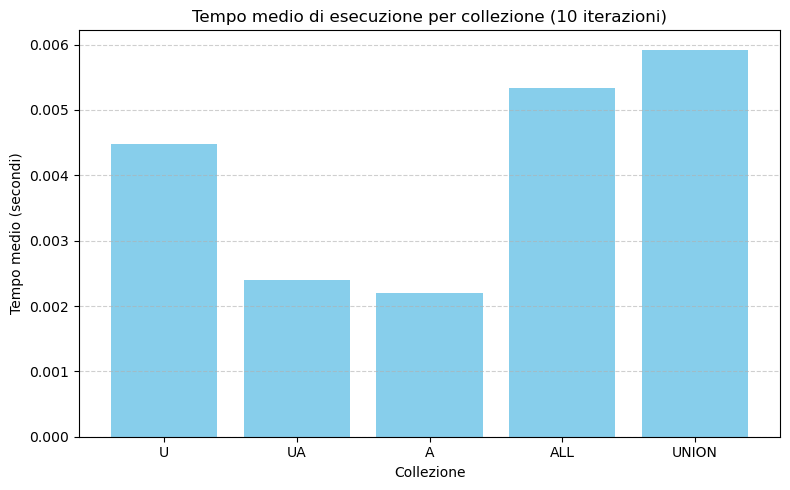


 Tempi medi di esecuzione (su 10 iterazioni):
  U: 0.0045 s
  UA: 0.0024 s
  A: 0.0022 s
  ALL: 0.0053 s
  UNION: 0.0059 s


In [10]:
# Connessione a MongoDB
client = MongoClient("mongodb://localhost:27017/")
db = client["homework_2024"]

# Numero di ripetizioni per la media
N = 10

# Definizione dei gruppi di collezioni da testare
collection_groups = {
    "U": ["movies_U"],
    "UA": ["movies_UA"],
    "A": ["movies_A"],
    "ALL": ["all"],
    "UNION": ["movies_U", "movies_UA", "movies_A"]
}

# Risultati temporali
times = {name: [] for name in collection_groups.keys()}

# Eseguo la pipeline per ciascun gruppo, ripetuta N volte
for i in range(N):
    print(f"\nIterazione {i+1}/{N}")
    for name, coll_list in collection_groups.items():
        _, elapsed = get_top5_by_genre(db, coll_list, verbose=False)
        times[name].append(elapsed)
        print(f"  {name}: {elapsed:.4f} s")

# Calcolo le medie
avg_times = {name: sum(vals)/len(vals) for name, vals in times.items()}

# --- Plot dei risultati ---
plt.figure(figsize=(8,5))
plt.bar(avg_times.keys(), avg_times.values(), color='skyblue')
plt.title("Tempo medio di esecuzione per collezione (10 iterazioni)")
plt.ylabel("Tempo medio (secondi)")
plt.xlabel("Collezione")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# --- Stampa delle medie ---
print("\n Tempi medi di esecuzione (su 10 iterazioni):")
for name, avg in avg_times.items():
    print(f"  {name}: {avg:.4f} s")

<p>Altre query che possono essere eseguite in maniera analoga:
    <ul>
        <li>Trovare tutti i film pubblicati dopo il 2015 raggruppati per genere (ad esempio "fantascienza" o "giallo"); visualizzare in un istogramma il numero di film per ogni genere</li>
        <li>Trovare il film più vecchio e più recente per ogni genere</li>
        <li>Trovare il film più vecchio con la valutazione più alta</li>
        <li>Trovare i primi 5 film con la maggiore durata</li>
        <li>Trovare l’ammontare degli incassi per ogni genere e visualizzarlo in un istogramma</li>
    </ul>
</p>

<hr>
<h1>Sistema di raccomandazione</h1>
<p>Si supponga ora che il docente di Sistemi Informativi Evoluti e Big Data abbia una predilezione per il genere Sci-Fi e Adventure, ma non ami particolarmente i film troppo lunghi. Proporre un algoritmo di raccomandazione basato su queste preferenze e che gli suggerisca 3 film da guardare. Come si classificherebbe tale algoritmo?</p>

In [11]:
pipeline = [
    # 1. Esplodo i generi per gestirli singolarmente
    {"$unwind": "$Genre"},

    # 2️. Calcolo il punteggio per genere: 1 se è Sci-Fi o Adventure, 0 altrimenti
    {"$addFields": {
        "Genre_Score": {
            "$cond": [
                {"$in": ["$Genre", ["Sci-Fi", "Adventure"]]},
                1,
                0
            ]
        }
    }},

    # 3️. Raggruppo per film, calcolando la somma dei punteggi sui generi
    {"$group": {
        "_id": "$Series_Title",
        "Genres": {"$addToSet": "$Genre"},
        "Genre_Score": {"$sum": "$Genre_Score"},
        "IMDB_Rating": {"$first": "$IMDB_Rating"},
        "Runtime": {"$first": "$Runtime"}
    }},

    # 4️. Tengo solo i film con almeno un genere preferito
    {"$match": {"Genre_Score": {"$gt": 0}}},

    # 5️. Ordino per durata crescente (film più brevi prima)
    {"$sort": {"Runtime": 1}},

    # 6️. Prendo solo i primi 3
    {"$limit": 3},

    # 7️. Output finale pulito
    {"$project": {
        "_id": 0,
        "Title": "$_id",
        "Genres": 1,
        "IMDB_Rating": 1,
        "Runtime": 1
    }}
]

list(collezione_all.aggregate(pipeline))

[{'Genres': ['Mystery', 'Sci-Fi', 'Thriller'],
  'IMDB_Rating': 7.6,
  'Runtime': '100 min',
  'Title': 'Dark City'},
 {'Genres': ['Comedy', 'Animation', 'Adventure'],
  'IMDB_Rating': 7.7,
  'Runtime': '100 min',
  'Title': 'Tangled'},
 {'Genres': ['Comedy', 'Animation', 'Adventure'],
  'IMDB_Rating': 8.1,
  'Runtime': '100 min',
  'Title': 'Soul'}]

<p><b>Risposta alla domanda:</b> si tratta di un <i>content-based recommender system</i></p>

<p>Verificare se esistono nel database dei film classificati sia come Sci-Fi e Adventure, che non durano più di 90 minuti. Se sì, visualizzare i primi 3 (in base al rating) e confrontare il risultato di questa query rispetto all’output dell’algoritmo di raccomandazione. Se non esistono film con questi requisiti nel database, provare a ipotizzare quale potrebbe essere un rating di un film classificato sia come Sci-Fi e Adventure, che non duri più di 90 minuti. Confrontare anche in quest’ultimo caso la previsione con quanto suggerito dall’algoritmo di raccomandazione.</p>

<p><b>Procedura:</b> dopo aver verificato l'esistenza o meno di film classificati come Sci-Fi e Adventure che durano meno di 90 minuti, procediamo cercando la correlazione tra il rating e la durata per i soli film che appartengono ad entrambi i generi.</p>

In [12]:
# Pipeline
pipeline = [
    # 1️. Filtra film che hanno entrambi i generi Sci-Fi e Adventure
    {"$match": {"Genre": {"$all": ["Sci-Fi", "Adventure"]}}},

    # 2️. Converto Runtime in intero (es. "85 min" -> 85)
    {"$addFields": {
        "RuntimeInt": {
            "$toInt": {"$arrayElemAt": [{"$split": ["$Runtime", " "]}, 0]}
        }
    }},

    # 3️. Filtro per durata < 90 minuti
    {"$match": {"RuntimeInt": {"$lt": 100}}},

    # 4️. Se vuoi, ordina per durata crescente
    {"$sort": {"RuntimeInt": 1}},

    # 5️. Seleziona i campi da visualizzare
    {"$project": {
        "_id": 0,
        "Title": "$Series_Title",
        "Genres": "$Genre",
        "IMDB_Rating": 1,
        "Runtime": 1
    }}
]

# Esecuzione
result = list(collezione_all.aggregate(pipeline))

# Conversione in DataFrame per visualizzare comodamente
df = pd.DataFrame(result)
print(df)

  Runtime  IMDB_Rating      Title                       Genres
0  96 min          7.6  Mad Max 2  [Action, Adventure, Sci-Fi]


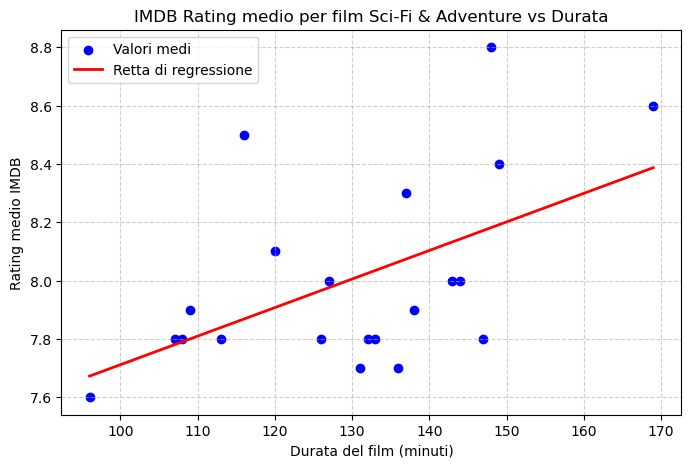

In [13]:
# --- Pipeline MongoDB ---
pipeline = [
    # 1. Filtra solo Sci-Fi o Adventure
    {"$match": {"Genre": {"$all": ["Sci-Fi", "Adventure"]}}},

    # 2. Estrai il numero della durata come intero (da "142 min" → 142)
    {"$addFields": {
        "RuntimeInt": {
            "$toInt": { "$arrayElemAt": [{ "$split": ["$Runtime", " "] }, 0] }
        }
    }},

    # 3. Raggruppa per durata, calcolando la media del rating
    {"$group": {
        "_id": "$RuntimeInt",
        "avg_rating": {"$avg": "$IMDB_Rating"},
        "count": {"$sum": 1}
    }},

    # 4. Ordina per durata crescente
    {"$sort": {"_id": 1}}
]

# --- Esecuzione query ---
result = list(collezione_all.aggregate(pipeline))

# --- Conversione in DataFrame ---
df = pd.DataFrame(result)
df.rename(columns={"_id": "Runtime", "avg_rating": "Average Rating"}, inplace=True)

# --- Plot base ---
plt.figure(figsize=(8, 5))
plt.scatter(df["Runtime"], df["Average Rating"], color="blue", label="Valori medi")

# --- Calcolo retta di regressione (y = m*x + b) ---
x = df["Runtime"].values
y = df["Average Rating"].values

# np.polyfit calcola i coefficienti della retta di regressione
m, b = np.polyfit(x, y, 1)
y_pred = m * x + b

# --- Disegno la retta ---
plt.plot(x, y_pred, color="red", linewidth=2, label="Retta di regressione")

# --- Etichette e legenda ---
plt.title("IMDB Rating medio per film Sci-Fi & Adventure vs Durata")
plt.xlabel("Durata del film (minuti)")
plt.ylabel("Rating medio IMDB")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

In [14]:
# Stima del rating per film da 90 minuti
runtime_test = 90
predicted_rating = m * runtime_test + b
print(f"Rating stimato per un film Sci-Fi e Adventure di {runtime_test} minuti: {predicted_rating:.1f}")

Rating stimato per un film Sci-Fi e Adventure di 90 minuti: 7.6
